# 08 — The offset as a function of which timescale

**What this notebook does:** Shows that TCX−TCB *as a function of TCB* and *as a function of TCX* are different functions, implements the re-parameterisation, and validates it against Klioner's independently integrated inverse products for Mars and Earth.

**Key results:** Effect ≈ 0.30 µs/cy (TCM) and 0.69 µs/cy (TCG), scaling as $L_X^2$; TEMPUS vs Klioner agreement ~0.007 ns detrended.

**Required data files:** Klioner's forward and inverse series, `../data/time_ephem/tcx19a_{TCM,TCG}_m100_p100_asc_pos_TCB.asc` and `tcx19a_TCB_m100_p100_asc_pos_{TCM,TCG}.asc`; `../data/ephem/inpop19a_TCB_m100_p100_tcg.dat`. §3 reuses notebook 02's Mars run (`../output/nb02_tcm_m100_p100_INPOP19aTCB.csv`) and integrates it only if missing.

**Reference:** S. A. Klioner, *Relativistic time scales in the Solar system*, 2026, arXiv:2604.16006, §4.


In [1]:
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from tempus import jd_split, jd_tt_to_tcb
from tempus.chebycode import ChebySeries
from tempus.ephem import CalcephEphem
from tempus.model import DAY_S, boost_term, jd_grid, relabel_to_tcx
from nb_utils import jd_to_et, yr_from_jd, plot_compare_2timescales, run_tempus_integration

eph_file = Path("../data/ephem/inpop19a_TCB_m100_p100_tcg.dat").resolve()


## 1 · Two parameterisations of the same offset

With $t=\mathrm{TCB}$, $T=\mathrm{TCX}$ and $F(t)=d\mathrm{TCX}/d\mathrm{TCB}-1$ (the TEMPUS integrand), the forward offset $\Delta t(t)=\mathrm{TCX}-\mathrm{TCB}$ obeys

$$T = t + \Delta t(t), \qquad \frac{d\,\Delta t}{dt} = F(t) \tag{Klioner 18, 20}$$

and the same offset tabulated against the local time, $\Delta T(T)$ with $t=T-\Delta T(T)$, obeys

$$\frac{d\,\Delta T}{dT} = \frac{F(T-\Delta T)}{1+F(T-\Delta T)} \tag{Klioner 21}$$

— a Jacobian factor **and** a self-referential argument. To first order

$$\Delta T(T) = \Delta t(T) - F(T)\,\Delta t(T) + \mathcal{O}(\dot F \Delta t^2),$$

so evaluating the forward series at a numerically equal argument is wrong by $F\cdot\Delta \approx L_X^2\,\tau$ — linear in elapsed time, and quadratic in the body's $L_X$.

**Eq. 21 need not be integrated.** A sampled offset already carries the answer: each sample is one *event* with two time labels. At native epoch $t_k$ the offset is $y_k = t - \mathrm{TCX}$, so the same event's TCX label is $t_k - y_k/86400$ since t is in units day and y in seconds, and

$$\big(t_k - y_k/86400,\; y_k\big)$$

*is* the offset tabulated against TCX — exactly, with no interpolation and no iteration. `model.relabel_to_tcx` is this one-line map; the values are untouched and only the axis label is relabelled, which is precisely what re-parameterisation means. The resulting TCX grid is non-uniform by $O(F)\sim10^{-8}$, which a piecewise-Chebyshev fit does not care about.

## 2 · The effect, and validation against Klioner (Mars)

The TU Dresden time ephemerides ship both parameterisations of the *same* quantity TCX−TCB:

- `tcx19a_TCM_..._pos_TCB.asc` — TCM−TCB wrt **TCB** (forward),
- `tcx19a_TCB_..._pos_TCM.asc` — TCM−TCB wrt **TCM** (inverse, Klioner's ODEX integration of Eq. 21).

Klioner's site names Mars `TCMar`; `scripts/fetch_klioner_asc.py` saves both files as `TCM`.

Differencing them at equal numeric argument isolates the effect.

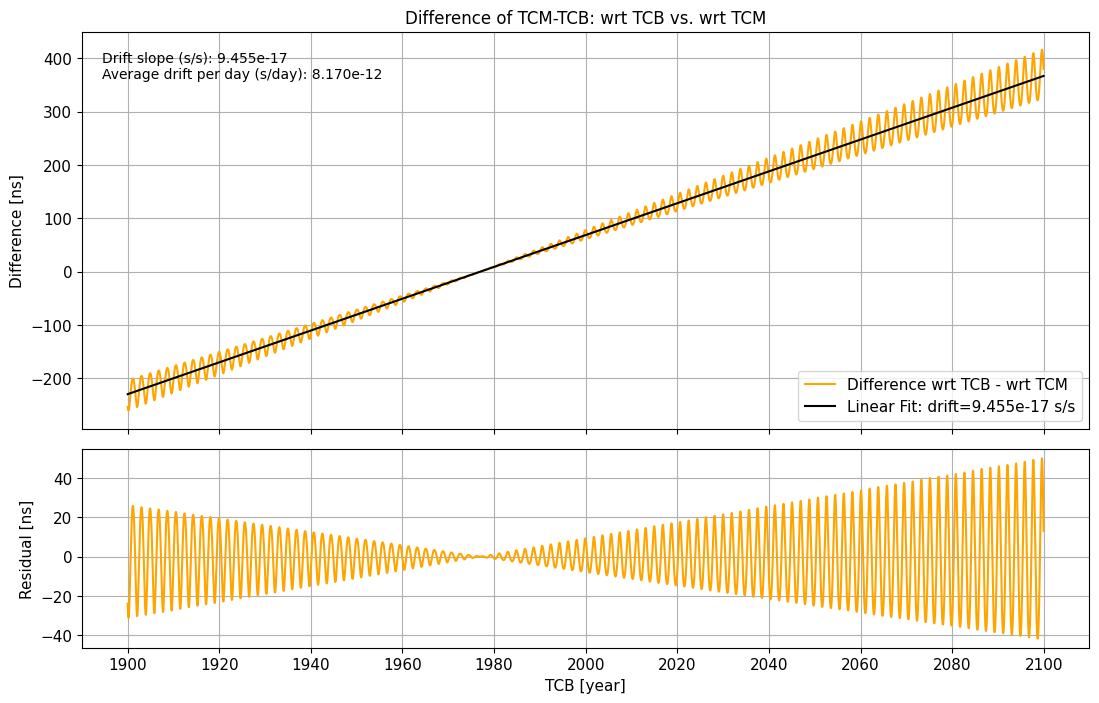

Drift slope (s/s): 9.455485034744153e-17
Average drift per day (ps/day): 8.16953907001895
Average drift per century (ns/cy): 298.3924145324421
Min and Max of detrended TCM-TCB (ns): -41.7938, 50.1452


In [2]:
g  = jd_grid(2415030, 0.3, 2488050, 0.3, 0.75)          # 200 yr evaluation grid
et = jd_to_et(g.jd_int + g.jd_frac)

mar_fwd = ChebySeries.from_asc("../data/time_ephem/tcx19a_TCM_m100_p100_asc_pos_TCB.asc")
mar_inv = ChebySeries.from_asc("../data/time_ephem/tcx19a_TCB_m100_p100_asc_pos_TCM.asc")

plot_compare_2timescales(et, mar_fwd.evaluate(g.jd_int, g.jd_frac), "wrt TCB", 
                         mar_inv.evaluate(g.jd_int, g.jd_frac), "wrt TCM", 
                         label="TCM-TCB", x_tick=20, overview=False)

A linear divergence of ~0.30 µs/cy, zero at the 1977 origin where both files are anchored. Not a sign flip, or simple linear scaling. A meaningful difference if one is not careful or aware which parametrisation for the offset is used.

Repeating for Earth tests the predicted $L_X^2$ scaling of the effect:

In [3]:
yr = (g.jd_int - 2451545 + g.jd_frac) / 365.25

earth_fwd = ChebySeries.from_asc("../data/time_ephem/tcx19a_TCG_m100_p100_asc_pos_TCB.asc")
earth_inv = ChebySeries.from_asc("../data/time_ephem/tcx19a_TCB_m100_p100_asc_pos_TCG.asc")

BODIES = {"TCM (Mars)":  (mar_fwd, mar_inv, 0.97e-8), "TCG (Earth)": (earth_fwd, earth_inv, 1.48e-8)}

eff = {}
for name, (fwd, inv, L) in BODIES.items():
    eff[name] = np.polyfit(yr, inv.evaluate(g.jd_int, g.jd_frac) - fwd.evaluate(g.jd_int, g.jd_frac), 1)[0] * 100 * 1e6
    print(f"{name:12s} L={L:.2e}  effect {eff[name]:+.3f} µs/cy")

print(f"\neffect ratio TCG/TCM = {eff['TCG (Earth)']/eff['TCM (Mars)']:.2f}   "
      f"predicted (L_G/L_M)^2 = {(1.48/0.97)**2:.2f}")

TCM (Mars)   L=9.70e-09  effect -0.298 µs/cy
TCG (Earth)  L=1.48e-08  effect -0.692 µs/cy

effect ratio TCG/TCM = 2.32   predicted (L_G/L_M)^2 = 2.33


The Earth/Mars effect ratio, using Klioner's files, matches the $L_X^2$​ scaling, confirming the effect is $F\cdot\Delta≈L_X\cdot(L_X\cdot\tau)$.

**Now to validate our implementation**, with no TEMPUS dynamics involved: sample Klioner's *forward* file, apply only `tempus.model.relabel_to_tcx()`, and compare against his *inverse* file. This isolates the re-parameterisation itself — an exact per-event relabelling (ours) vs a numerical integration of Eq. 21 with the ODEX solver (his).

In [4]:
# Re-label Klioner's forward series (TCB-TCM = -fwd, wrt TCB) onto TCM and refit
g_nat = jd_grid(2415025, 0.5, 2488065, 0.5, 0.75)        # native (TCB) sampling grid
y   = -mar_fwd.evaluate(g_nat.jd_int, g_nat.jd_frac)     # y = TCB - TCM at native epochs
tcm = relabel_to_tcx(g_nat, y)                           # same values, TCM labels
mar_ours = ChebySeries.from_samples(tcm.jd_int, tcm.jd_frac, y, granule_len=3, order=11, npoints=10, dist=2)


max |TEMPUS relabel - Klioner ODEX|: 5.86 ps


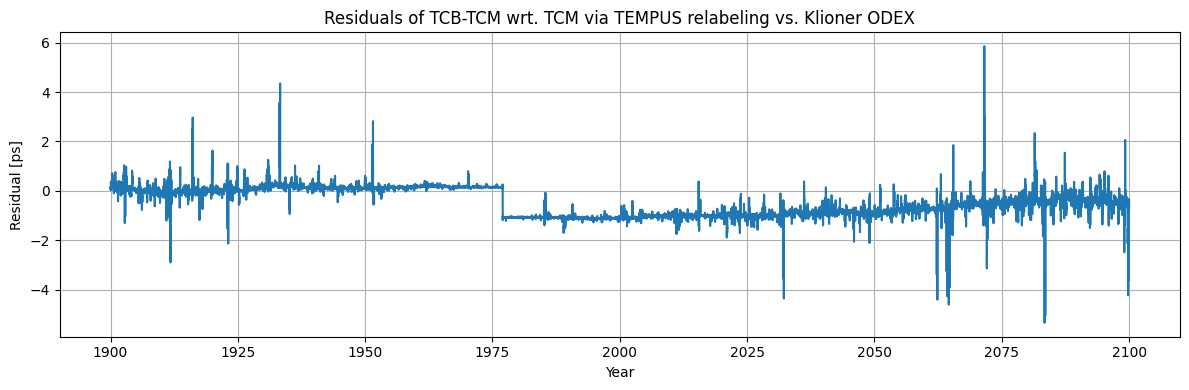

In [5]:
yr    = yr_from_jd(g_nat.jd_int + g_nat.jd_frac)
resid = mar_ours.evaluate(g_nat.jd_int, g_nat.jd_frac) + mar_inv.evaluate(g_nat.jd_int, g_nat.jd_frac)   # (TCB-TCM) + (TCM-TCB)
print(f"max |TEMPUS relabel - Klioner ODEX|: {np.max(np.abs(resid))*1e12:.2f} ps")

plt.figure(figsize=(12, 4))
plt.plot(yr, resid*1e12, label="TEMPUS relabel vs. Klioner ODEX")
plt.title("Residuals of TCB-TCM wrt. TCM via TEMPUS relabeling vs. Klioner ODEX")
plt.xlabel("Year")
plt.ylabel("Residual [ps]")
plt.grid(True)
plt.tight_layout()
plt.show()


An exact relabelling and an independent ODE integration of Eq. 21 agree at the picosecond level, validating our simple relabelling approach.


## 3 · End-to-end for Mars: `tempus integrate` → `tempus chebyshev --also-wrt-tcx`

Everything above, run as a pipeline on our own integration and compared against Klioner's Mars inverse file. The integration mirrors his setup — INPOP19a (TCB flavour), planets only (no asteroids), 0.75 d cadence, ±100 yr about J2000 — which is exactly notebook 02's Mars run, so that CSV is reused and only integrated here if missing.

```bash
tempus integrate \
  --eph-file ../data/ephem/inpop19a_TCB_m100_p100_tcg.dat \
  --jd-start <J2000_TCB - 36525> --jd-end <J2000_TCB + 36525> --jd-step 0.75 \
  --target MARS_BARYCENTER --center SSB --ext auto \
  --out ../output/nb02_tcm_m100_p100_INPOP19aTCB.csv

tempus chebyshev ../output/nb02_tcm_m100_p100_INPOP19aTCB.csv \
  --anchor --also-wrt-tcx --granule-len 3 --max-err 1e-9
```

Both parameterisations are written in one call: `…INPOP19aTCB.asc` (native, wrt TCB) and `…INPOP19aTCB_tcx.asc` (wrt TCM).

**The anchor.** The TCX labels are built from $\Delta$ itself ($T = t - \Delta/86400$), so an additive constant in $\Delta$ shifts every label. By default TEMPUS zeroes $\Delta$ at the integration start, unless `--zero` is used; the IAU convention zeroes at the 1977 origin. `--anchor` (bare = 1977) also aligns them, and doesn't hurt even if `--zero´ was used before — without the correct zero the relabelled axis is a private variant of TCM, offset by $\Delta(1900)$, which appears as a $\dot{(\text{periodic})}\cdot\Delta$ residual against Klioner.


In [ ]:
# notebook 02's Mars run (same file, span, step and perturbers); integrated only if missing
mars_csv = Path("../output/nb02_tcm_m100_p100_INPOP19aTCB.csv").resolve()

if mars_csv.is_file():
    print(f"  have {mars_csv.name}")
else:
    start = jd_tt_to_tcb(*jd_split(2451545.0), eph_file)   # J2000.0 TT -> TCB
    run_tempus_integration(
        eph_file=eph_file, out=mars_csv,
        start=start - 36525, end=start + 36525, jd_step=0.75, zero=True,
        target="MARS_BARYCENTER", center="SSB", ext="auto",   # planets only, as Klioner
    )


  have nb02_tcm_m100_p100_INPOP19aTCB.csv


In [7]:
# writes ..._INPOP19aTCB.asc (wrt TCB) and ..._INPOP19aTCB_tcx.asc (wrt TCM) next to the CSV
print(subprocess.run(
    ["tempus", "chebyshev", str(mars_csv),
     "--anchor", "--also-wrt-tcx", "--granule-len", "3", "--max-err", "1e-9"],
    capture_output=True, text=True, check=True).stdout)


  anchored: series zeroed at JD 2443144 + 0.5003725 (shift +3.7422755866378665e-14 s)
ChebyshevSeries(order=11, n_granules=24350, ndim=1, jd=[2415020.0, 2488069.3])
──────────────────────────────────────────────────
  Continuity   C⁰ max jump  : 7.82e-14
               C¹ max jump  : 1.94e-12
  Truncation   last coeff   : 7.11e-15
               decay-rate   : 0.00
               converged    : False
──────────────────────────────────────────────────
  Samples      max  error : 9.94760e-14
               RMS  error : 3.55286e-14
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb02_tcm_m100_p100_INPOP19aTCB.asc (wrt TCB)

ChebyshevSeries(order=11, n_granules=24350, ndim=1, jd=[2415020.0, 2488069.2])
──────────────────────────────────────────────────
  Continuity   C⁰ max jump  : 8.53e-14
               C¹ max jump  : 1.94e-12
  Truncation   last coeff   : 1.07e-14
               decay-rate   : 0.00
               converged    : False
────────────────────────────────────────────

1977 stitching jump removed: -7.043e-13 s (-0.70 ps)


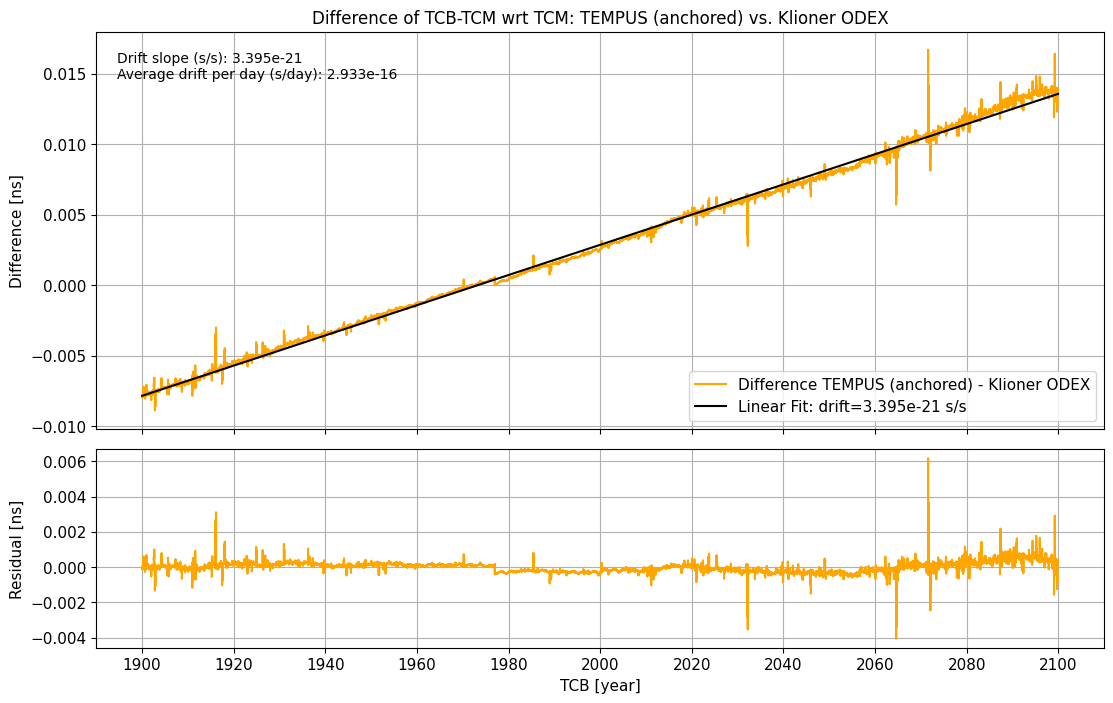

Drift slope (s/s): 3.3945034997112526e-21
Average drift per day (ps/day): 0.00029328510237505224
Average drift per century (ns/cy): 0.010712238364248783
Min and Max of detrended TCB-TCM wrt TCM (ns): -0.0041, 0.0062


In [8]:
# --- analysis: TEMPUS Mars product (wrt TCM) vs Klioner's Mars inverse file ---
mars_tempus = ChebySeries.from_asc("../output/nb02_tcm_m100_p100_INPOP19aTCB_tcx.asc")

plot_compare_2timescales(et,
                         mars_tempus.evaluate(g.jd_int, g.jd_frac), "TEMPUS (anchored)",
                         -mar_inv.evaluate(g.jd_int, g.jd_frac), "Klioner ODEX",
                         label="TCB-TCM wrt TCM", x_tick=20, fix_1977_jump=True, overview=False)

End-to-end — integration, fit, anchor, inversion — against an independently integrated reference. The residual now carries only the TEMPUS dynamical model difference (perturber set, integrator), free of the annual signature an unanchored axis would produce.

## 4 · Summary

| check | result |
|---|---|
| effect for Mars: wrt TCM − wrt TCB (Klioner's two files) | −0.298 µs/cy |
| effect for Earth (TCG) | −0.692 µs/cy; ratio 2.32 vs predicted $(L_G/L_M)^2$ = 2.33 |
| TEMPUS relabelling vs Klioner's ODEX inverse, Mars (no TEMPUS dynamics) | 5.9 ps max |
| end-to-end TEMPUS vs Klioner, TCB − TCM wrt TCM | 0.011 ns/cy drift, −4.1 … +6.2 ps detrended |


## Appendix · Parameterisation is not simultaneity

A natural objection: doesn't the axis choice in §1 just repeat a simultaneity choice, like the TCG−TCL pairing question in notebook 07? No — different question, because TCX−TCB lives on **one** worldline and TCG−TCL needs **two**.

| | **Parameterisation** (this notebook) | **Simultaneity** (notebook 07) |
|---|---|---|
| worldlines | one — e.g. TCX−TCB | two — e.g. TCG−TCL |
| what is free | which label goes on the axis | which pair of events a row means |
| effect on the values | **none** — rows only move along the axis | rows change value |
| size | $F\cdot\Delta \approx L_X^2\tau$: 0.69 µs/cy (TCG) | $\|\mathbf{v}_E\cdot\mathbf{r}_{LE}\|/c^2 \lesssim 136$ µs, monthly |
| character | secular, unbounded | periodic, bounded |
| metadata | `argument_timescale` | `simultaneity` |

The two are orthogonal — a TCG−TCL product at TCB-simultaneity can still be tabulated against TCB or against TCG — hence two independent metadata fields.

**Why:** in the IAU 2000 1PN transformation (notebook 07, §2) a simultaneity convention can enter only through the spatial term $\mathbf{v}_E\cdot(\mathbf{x}-\mathbf{x}_E)/c^2$. A product on one body-centre worldline has $\mathbf{x}=\mathbf{x}_E$, so that term is multiplied by zero: one event carries two coordinate labels, and there is nothing to pair. What remains free is only which label (TCB or TCX) goes on the axis — the axis moves, no value changes (§1). The cell below puts the two effects side by side.


simultaneity    |v_E.r_LE|/c^2 peak :     134.45 us   bounded, monthly
parameterisation      F.Delta @ 60 d :   1.14e-03 us   secular
                             @ 1 cy :      0.691 us


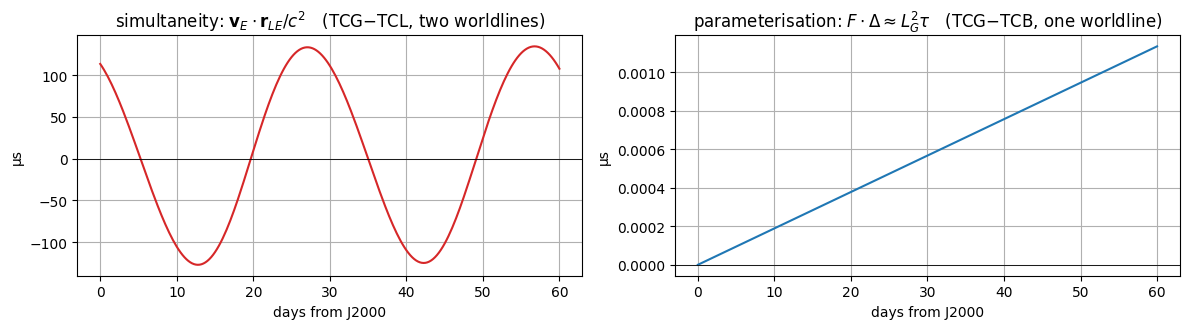

In [9]:
# simultaneity: the gap between the equal-TCB and the geocentric pairing, Earth-Moon, 60 d
g_sim = jd_grid(2451545, 0.0, 2451605, 0.0, 0.25)
eph = CalcephEphem.open(["../data/ephem/inpop19a_TCB_m100_p100_tcg.dat"])
boost = boost_term(eph, jd_int=g_sim.jd_int, jd_frac=g_sim.jd_frac, target=301, center=399)  # Moon wrt Earth
eph.close()

# parameterisation: F.Delta ~ L_G^2 * tau on the same span
L_G_ = 1.48e-8
d_sim = (g_sim.jd_int - g_sim.jd_int[0]) + g_sim.jd_frac
param = L_G_**2 * d_sim * float(DAY_S)

print(f"simultaneity    |v_E.r_LE|/c^2 peak : {np.abs(boost).max()*1e6:10.2f} us   bounded, monthly")
print(f"parameterisation      F.Delta @ 60 d : {param[-1]*1e6:10.2e} us   secular")
print(f"                             @ 1 cy : {L_G_**2*3.156e9*1e6:10.3f} us")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(d_sim, boost*1e6, color="C3")
ax[0].set_title(r"simultaneity: $\mathbf{v}_E\cdot\mathbf{r}_{LE}/c^2$   (TCG$-$TCL, two worldlines)")
ax[1].plot(d_sim, param*1e6, color="C0")
ax[1].set_title(r"parameterisation: $F\cdot\Delta \approx L_G^2\tau$   (TCG$-$TCB, one worldline)")
for a in ax:
    a.axhline(0, lw=0.6, color="k"); a.grid(True)
    a.set_xlabel("days from J2000"); a.set_ylabel("µs")
plt.tight_layout(); plt.show()